# 5 · Sensibilità alla calibrazione (leave-one-view-out)

Con 6 viste del master e un solo scatto per solido non si può stimare un errore con la statistica classica. Si misura invece quanto cambia il risultato ricalibrando senza una vista alla volta (jackknife): la vista esclusa lo è dalla camera e dal piano della lama. La vista a z = 350 mm non si esclude perché definisce il riferimento.

Lo stesso calcolo su dati sintetici dice quanto della sensibilità è dell'algoritmo e quanto del setup.

In [1]:
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA, FIGURES = ROOT / "data", ROOT / "docs" / "figures"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

from lightsheet3d.pipeline import calibrate_camera
from lightsheet3d.solids import CORPO5, CORPO6
from lightsheet3d.synthetic import Scene, write_dataset
from lightsheet3d.uncertainty import jackknife_se, leave_one_view_out

## Dati reali

In [2]:
camera = calibrate_camera(DATA / "camera_calibration")
print(f"centri scartati come errati: {int((~camera.inliers).sum())} su {len(camera.inliers)} "
      f"(per vista: { {int(z): int((~camera.inliers[camera.view_ids == z]).sum()) for z in sorted(set(camera.view_ids))} })")

REAL = {
    "Corpo 6": leave_one_view_out(camera, DATA / "light_plane_calibration", DATA / "scans" / "30o34.jpg", CORPO6),
    "Corpo 5": leave_one_view_out(camera, DATA / "light_plane_calibration", DATA / "scans" / "30o3.jpg", CORPO5),
}
for name, runs in REAL.items():
    print(f"\n{name}")
    for r in runs:
        label = "completa" if r.excluded is None else f"senza z = {r.excluded}"
        print(f"  {label:15s} distanza mediana {r.median:.2f} mm | altezze {np.round(r.heights, 1).tolist()}")

centri scartati come errati: 9 su 1028 (per vista: {300: 0, 310: 0, 320: 9, 330: 0, 340: 0, 350: 0})



Corpo 6
  completa        distanza mediana 0.55 mm | altezze [44.4, 24.1, 44.6]
  senza z = 300   distanza mediana 1.43 mm | altezze [39.9, 21.5, 40.1]
  senza z = 310   distanza mediana 0.66 mm | altezze [44.1, 23.9, 44.3]
  senza z = 320   distanza mediana 0.49 mm | altezze [45.0, 24.6, 45.2]
  senza z = 330   distanza mediana 0.75 mm | altezze [43.8, 23.7, 43.9]
  senza z = 340   distanza mediana 0.73 mm | altezze [48.2, 26.3, 48.5]

Corpo 5
  completa        distanza mediana 0.62 mm | altezze [34.9, 29.7, 45.5]
  senza z = 300   distanza mediana 1.45 mm | altezze [31.2, 26.5, 40.9]
  senza z = 310   distanza mediana 0.78 mm | altezze [34.7, 29.5, 45.3]
  senza z = 320   distanza mediana 0.64 mm | altezze [35.4, 30.2, 46.1]
  senza z = 330   distanza mediana 0.80 mm | altezze [34.4, 29.2, 44.9]
  senza z = 340   distanza mediana 1.85 mm | altezze [38.1, 32.4, 49.6]


## Dati sintetici (stessa geometria, rumore 0.5 px)

In [3]:
with tempfile.TemporaryDirectory() as tmp:
    root, scan = write_dataset(Scene(), CORPO6, tmp, noise_px=0.5)
    cam = calibrate_camera(root / "camera_calibration")
    SYN = {"Sintetico, Corpo 6": leave_one_view_out(cam, root / "light_plane_calibration", root / "scans" / scan, CORPO6)}
for r in SYN["Sintetico, Corpo 6"]:
    label = "completa" if r.excluded is None else f"senza z = {r.excluded}"
    print(f"  {label:15s} distanza mediana {r.median:.2f} mm | altezze {np.round(r.heights, 1).tolist()}")

  completa        distanza mediana 0.16 mm | altezze [45.1, 24.8, 45.3]
  senza z = 310   distanza mediana 0.17 mm | altezze [45.1, 24.8, 45.3]
  senza z = 320   distanza mediana 0.16 mm | altezze [45.1, 24.8, 45.3]
  senza z = 330   distanza mediana 0.16 mm | altezze [45.2, 24.8, 45.3]
  senza z = 340   distanza mediana 0.17 mm | altezze [45.1, 24.8, 45.3]


## Confronto

Corpo 6              variazione massima delle altezze 4.5 mm | errore standard jackknife della distanza mediana 0.64 mm
Corpo 5              variazione massima delle altezze 4.6 mm | errore standard jackknife della distanza mediana 0.93 mm
Sintetico, Corpo 6   variazione massima delle altezze 0.1 mm | errore standard jackknife della distanza mediana 0.01 mm


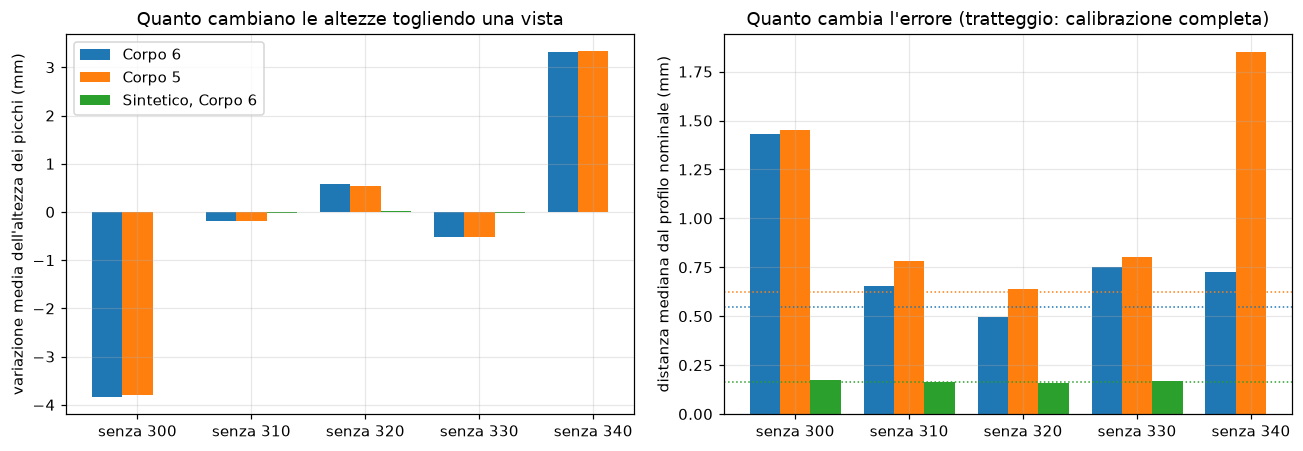

In [4]:
ALL = {**REAL, **SYN}
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4.2))
width = 0.8 / len(ALL)
for i, (name, runs) in enumerate(ALL.items()):
    full, loo = runs[0], runs[1:]
    x = np.arange(len(loo)) + i * width
    a.bar(x, [np.nanmean(r.heights - full.heights) for r in loo], width, label=name)
    b.bar(x, [r.median for r in loo], width, label=name)
    b.axhline(full.median, color=f"C{i}", ls=":", lw=1)
labels = [f"senza {r.excluded}" for r in next(iter(ALL.values()))[1:]]
for ax in (a, b):
    ax.set_xticks(np.arange(len(labels)) + width * (len(ALL) - 1) / 2, labels)
a.set(ylabel="variazione media dell'altezza dei picchi (mm)", title="Quanto cambiano le altezze togliendo una vista")
b.set(ylabel="distanza mediana dal profilo nominale (mm)", title="Quanto cambia l'errore (tratteggio: calibrazione completa)")
a.legend(); fig.tight_layout(); fig.savefig(FIGURES / "uncertainty_leave_one_view_out.png", bbox_inches="tight")

for name, runs in ALL.items():
    loo = runs[1:]
    spread = max(float(np.nanmax(np.abs(r.heights - runs[0].heights))) for r in loo)
    print(f"{name:20s} variazione massima delle altezze {spread:.1f} mm | errore standard jackknife della distanza mediana {jackknife_se([r.median for r in loo]):.2f} mm")

## Cosa mostra

* **Sintetico**: togliere una vista sposta le altezze di circa 0.1 mm. L'algoritmo, con dati coerenti, non dipende da una singola vista.
* **Reale**: togliere la vista a z = 300 mm abbassa le altezze di circa 4.5 mm, togliere quella a 340 mm le alza di circa 4 mm, e in entrambi i casi l'errore sul profilo raddoppia o peggio. Con tutte le viste il risultato è vicino al disegno, ma è un equilibrio fra viste che non sono coerenti fra loro, non una misura robusta.
* **Una correzione nata da qui**: senza una vista la camera migliorava molto (rms da 7.3 a 3.9 px togliendo la 320): contenevano 9 centri sbagliati, tutti nell'ultima colonna del master vicina al bordo dell'immagine, con residui di circa 67 px. Ora `calibrate_camera` li scarta (rms 3.6 px).